In [ ]:
# --------------------------------------------------
# Getting our data
# --------------------------------------------------

import kagglehub

path = kagglehub.dataset_download("brianleung2020/eeg-motor-movementimagery-dataset")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\ayman\.cache\kagglehub\datasets\brianleung2020\eeg-motor-movementimagery-dataset\versions\1


# importing

In [ ]:
# --------------------------------------------------
# Importing
# --------------------------------------------------

import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
import h5py
from tqdm import tqdm
import time
import mne
from mne.datasets import eegbci
from mne.io import read_raw_edf
from mne import concatenate_raws
from tqdm import tqdm

# pre proccessing

In [ ]:
# --------------------------------------------------
# defining variables for preprocessing
# --------------------------------------------------

WINDOW_SIZE = 160          # 1 second at 160 Hz
STEP = 160                 # no overlap
FS = 160                   # resample to 160 Hz


MAX_SUBJECTS = 109
MAX_WINDOWS_PER_RUN = 200  # cap windows per run (for speed, can increase)

BASE_PATH = "C:/Users/ayman/.cache/kagglehub/datasets/brianleung2020/eeg-motor-movementimagery-dataset/versions/1/files"


In [ ]:
# --------------------------------------------------
# deciding on channels to process
# --------------------------------------------------
DESIRED_CHANNELS = [
    'Fz',
    'FC3', 'FC1', 'FCz', 'FC2', 'FC4',
    'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6',
    'CP3', 'CP1', 'CPz',
]

In [ ]:
# --------------------------------------------------
# function for picking the channels 
# --------------------------------------------------

import re

def norm_ch_name(ch):
    # remove non-alphanumeric and uppercase
    return re.sub(r'[^A-Za-z0-9]', '', ch).upper()

DESIRED_NORM = {norm_ch_name(ch): ch for ch in DESIRED_CHANNELS}

def pick_16_channels(raw):
    """
    From an mne.Raw object, pick the 16 channels matching DESIRED_CHANNELS
    using case- and punctuation-insensitive matching.
    """
    actual_map = {norm_ch_name(ch): ch for ch in raw.ch_names}
    
    selected_actual = []
    for norm, original in DESIRED_NORM.items():
        if norm in actual_map:
            selected_actual.append(actual_map[norm])
        else:
            print(f"[WARN] Channel {original} (normalized {norm}) not found in raw.ch_names")
    
    
    raw = raw.copy().pick_channels(selected_actual)
    return raw


In [ ]:
# --------------------------------------------------
# preprocessing frequencies to only get the relevant with no artifactss 
# --------------------------------------------------

def preprocess_raw(raw, l_freq=4., h_freq=40.):
    raw = raw.copy()
    raw.filter(l_freq=l_freq, h_freq=h_freq, fir_design="firwin", verbose=False)
    return raw


In [ ]:
# --------------------------------------------------
# normalize with z score
# --------------------------------------------------

def normalize_window(win):
    """
    win: (time, channels) -> per-window, per-channel z-score.
    """
    mean = win.mean(axis=0, keepdims=True)
    std = win.std(axis=0, keepdims=True)
    std[std < 1e-6] = 1e-6
    return (win - mean) / std


# splitting: train, test, val

In [8]:
def split_run_paper(X_run, y_run):
    """
    90% train, 10% test, then 10% of train as validation.
    """
    # 90% train / 10% test
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X_run, y_run, test_size=0.1, shuffle=True, stratify=y_run
    )

    # 10% of the train as validation
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full, test_size=0.1, shuffle=True, stratify=y_train_full
    )

    return X_train, y_train, X_val, y_val, X_test, y_test


# loading the data

In [ ]:
def load_dataset_paper_style(base_path, max_subjects=MAX_SUBJECTS,
                             max_windows_per_run=MAX_WINDOWS_PER_RUN):
    
    all_subjects = sorted([s for s in os.listdir(base_path) if s.startswith("S")])
    subjects = all_subjects[:max_subjects]

    
    runs = [f"R{r:02d}" for r in range(5, 15)]

    X_train_list, y_train_list = [], []
    X_val_list,   y_val_list   = [], []
    X_test_list,  y_test_list  = [], []

    for subj in tqdm(subjects, desc="Subjects"):
        subj_path = os.path.join(base_path, subj)

        for run in runs:
            
            edf_files = [f for f in os.listdir(subj_path)
                         if f.endswith(".edf") and run in f]
            if not edf_files:
                continue

            edf_path = os.path.join(subj_path, edf_files[0])

            
            raw = mne.io.read_raw_edf(edf_path, preload=True, verbose=False)

            
            raw = preprocess_raw(raw, l_freq=4., h_freq=40.)

            
            raw = pick_16_channels(raw)

            
            data = raw.get_data()          # (16, time)
            data = data.T                  # (time, 16)
            n_samples = data.shape[0]

            windows = []
            labels  = []
            count = 0
            for start in range(0, n_samples - WINDOW_SIZE, STEP):
                if count >= max_windows_per_run:
                    break
                win = data[start:start+WINDOW_SIZE, :]    # (160, 16)
                win = normalize_window(win)

                windows.append(win)
                # label: subject index (0-based)
                labels.append(int(subj[1:]) - 1)
                count += 1

            if not windows:
                continue

            X_run = np.stack(windows).astype(np.float32)   # (N_run, 160, 16)
            y_run = np.array(labels, dtype=np.int32)

            Xt, yt, Xv, yv, Xs, ys = split_run_paper(X_run, y_run)

            X_train_list.append(Xt)
            y_train_list.append(yt)
            X_val_list.append(Xv)
            y_val_list.append(yv)
            X_test_list.append(Xs)
            y_test_list.append(ys)

    X_train = np.concatenate(X_train_list)
    y_train = np.concatenate(y_train_list)
    X_val   = np.concatenate(X_val_list)
    y_val   = np.concatenate(y_val_list)
    X_test  = np.concatenate(X_test_list)
    y_test  = np.concatenate(y_test_list)

    return X_train, y_train, X_val, y_val, X_test, y_test


In [10]:
import os
X_train, y_train, X_val, y_val, X_test, y_test = load_dataset_paper_style(
    BASE_PATH,
    max_subjects=MAX_SUBJECTS,
    max_windows_per_run=MAX_WINDOWS_PER_RUN
)

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape,   y_val.shape)
print("Test: ", X_test.shape,  y_test.shape)

n_channels = X_train.shape[-1]
n_classes = len(np.unique(y_train))

print("Channels:", n_channels)
print("Classes (subjects actually used):", n_classes)


Subjects:   0%|          | 0/109 [00:00<?, ?it/s]

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


Subjects:   1%|          | 1/109 [00:01<02:12,  1.23s/it]

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


Subjects:   2%|▏         | 2/109 [00:02<02:10,  1.22s/it]

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


... (218 outputs left out)

Subjects:  99%|█████████▉| 108/109 [02:37<00:01,  1.32s/it]

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


Subjects: 100%|██████████| 109/109 [02:38<00:00,  1.45s/it]


Train: (106437, 160, 16) (106437,)
Val:   (12141, 160, 16) (12141,)
Test:  (14069, 160, 16) (14069,)
Channels: 16
Classes (subjects actually used): 109


# defining model

In [11]:
def ConvLSTM_EEG(timesteps=WINDOW_SIZE, n_channels=16, n_classes=109):
    inp = tf.keras.Input(shape=(timesteps, n_channels))

    x = layers.BatchNormalization()(inp)
    
    for filters in [128, 256, 512, 1024]:
        x = layers.Conv1D(
            filters=filters,
            kernel_size=2,
            padding="same",
            activation="relu"
        )(x)

    x = layers.TimeDistributed(
        layers.Dense(192, activation="relu")
    )(x)
    x = layers.Dropout(0.5)(x)

    x = layers.LSTM(192, return_sequences=True)(x)
    x = layers.LSTM(192)(x)

    x = layers.Dense(256, activation="relu")(x)
    out = layers.Dense(n_classes, activation="softmax")(x)

    model = models.Model(inputs=inp, outputs=out)
    return model


model = ConvLSTM_EEG(
    timesteps=WINDOW_SIZE,
    n_channels=n_channels,
    n_classes=n_classes  # use len(subjects) actually present
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 16)        │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 160, 128)       │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 160, 256)       │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 160, 512)       │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 160, 1024)      │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 160, 192)       │       196,800 │
│ (TimeDistributed)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 160, 192)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 160, 192)       │       295,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 192)            │       295,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 109)            │        28,013 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,247,917 (8.58 MB)

 Trainable params: 2,247,885 (8.58 MB)

 Non-trainable params: 32 (128.00 B)

# model training 

In [12]:
# history = model.fit(
#     X_train, y_train,
#     validation_data=(X_val, y_val),
#     epochs=20,            # start with 20–30 to test; then go higher
#     batch_size=80,         # same batch size commonly used in replications
#     callbacks=[
#         tf.keras.callbacks.EarlyStopping(
#             monitor="val_loss",
#             patience=10,
#             restore_best_weights=True
#         ),
#         tf.keras.callbacks.ReduceLROnPlateau(
#             monitor="val_loss",
#             factor=0.5,
#             patience=5,
#             min_lr=1e-6
#         )
#     ]
# )

# test_loss, test_acc = model.evaluate(X_test, y_test, batch_size=80)
# print("Test accuracy:", test_acc)

from tensorflow.keras.models import load_model
model = load_model("model.keras")


In [13]:
y_pred = model.predict(X_test, batch_size=80)
y_pred = np.argmax(y_pred, axis=1)

176/176 ━━━━━━━━━━━━━━━━━━━━ 54s 293ms/step


# testing and validation

In [14]:
print("y_test shape:", y_test.shape)
print("y_pred shape:", y_pred.shape)
print("Sample y_test:", y_test[:1000])
print("Sample y_pred:", y_pred[:1000])

y_test shape: (14069,)
y_pred shape: (14069,)
Sample y_test: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 

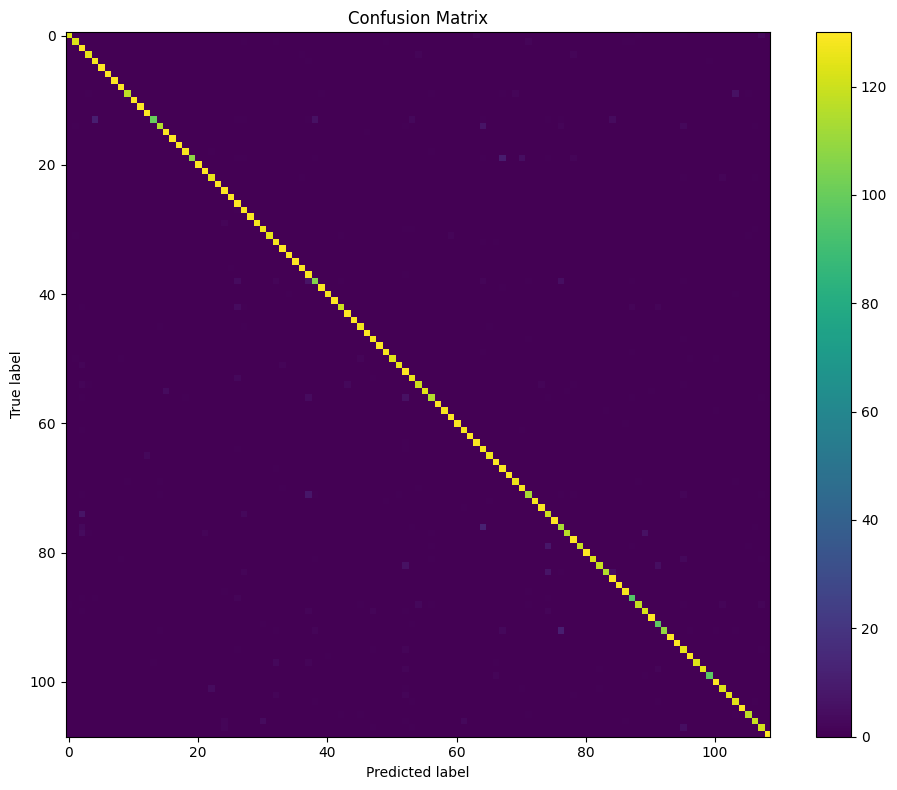

(0.9681569407918118, 0.9680255562450397, 0.9681149634703428)

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score
import matplotlib.pyplot as plt

acc = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation='nearest')
plt.title("Confusion Matrix")
plt.colorbar()
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

acc, f1_macro, f1_weighted


In [16]:
# from tensorflow.keras.models import load_model
# model = load_model("model.keras")

In [17]:
# model.summary()